## Batch 13 - EDA Assignment #7  (Richa Trivedi)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import statistics as stat
import matplotlib.pyplot as plt
import random
from scipy.stats import boxcox

In [4]:
# 1.Import the dataset and display the first 10 rows. Also print the shape of the dataset.
autosales_df=pd.read_csv('C:\\Users\\richa\\My_Learnings\\Practice_work\\EDA\\04_EDA\\Assignment\Auto_Sales.csv')
print("DataFrame 'autosales_df' loaded successfully. Displaying the first 10 rows:")
autosales_df.head(10)
autosales_df.shape

DataFrame 'autosales_df' loaded successfully. Displaying the first 10 rows:


(2747, 18)

In [5]:
#2.	Check the data types of all columns.
autosales_df.dtypes

ORDERNUMBER               int64
QUANTITYORDERED           int64
PRICEEACH               float64
SALES                   float64
ORDERDATE                object
DAYS_SINCE_LASTORDER      int64
STATUS                   object
PRODUCTLINE              object
MSRP                      int64
PRODUCTCODE              object
CUSTOMERNAME             object
ADDRESSLINE1             object
CITY                     object
POSTALCODE               object
COUNTRY                  object
CONTACTLASTNAME          object
CONTACTFIRSTNAME         object
DEALSIZE                 object
dtype: object

In [6]:
#3.	Check for any duplicates records and delete them
duplicate_rows = autosales_df[autosales_df.duplicated()]
duplicate_rows

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE


In [7]:
autosales_df.isnull().sum()

ORDERNUMBER             0
QUANTITYORDERED         0
PRICEEACH               0
SALES                   0
ORDERDATE               0
DAYS_SINCE_LASTORDER    0
STATUS                  0
PRODUCTLINE             0
MSRP                    0
PRODUCTCODE             0
CUSTOMERNAME            0
ADDRESSLINE1            0
CITY                    0
POSTALCODE              0
COUNTRY                 0
CONTACTLASTNAME         0
CONTACTFIRSTNAME        0
DEALSIZE                0
dtype: int64

In [8]:
#4.	Check for the outliers in all numerical variables with IQR method.
numerical_columns =autosales_df.select_dtypes(include=['float64', 'int64'])
numerical_columns


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,SALES,DAYS_SINCE_LASTORDER,MSRP
0,10107,30,95.70,2871.00,828,95
1,10121,34,81.35,2765.90,757,95
2,10134,41,94.74,3884.34,703,95
3,10145,45,83.26,3746.70,649,95
4,10168,36,96.66,3479.76,586,95
...,...,...,...,...,...,...
2742,10350,20,112.22,2244.40,2924,54
2743,10373,29,137.19,3978.51,2865,54
2744,10386,43,125.99,5417.57,2836,54
2745,10397,34,62.24,2116.16,2810,54


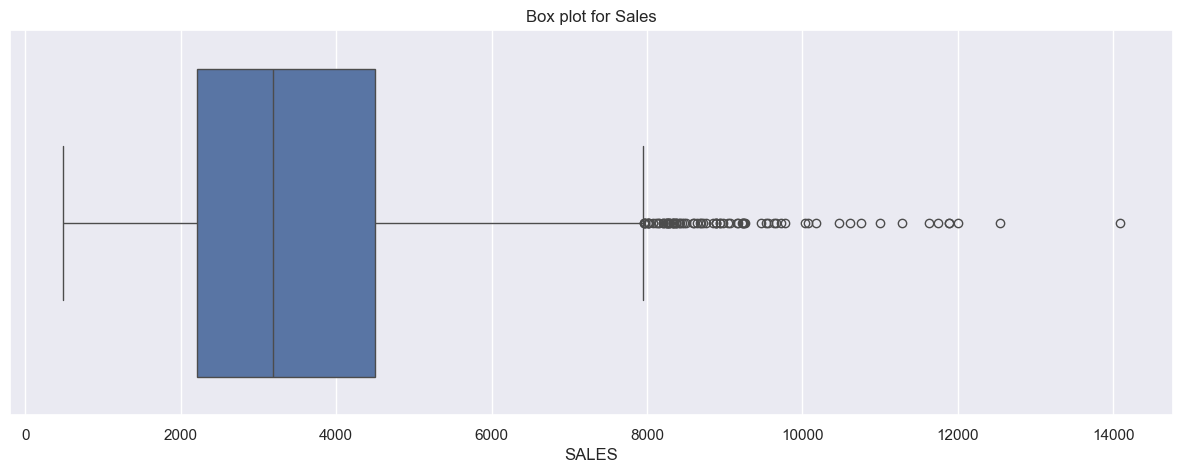

In [9]:
# Box plot for Sales
sns.set(rc={'figure.figsize':(15,5)})
sns.boxplot(data=numerical_columns['SALES'], orient="h")
plt.title('Box plot for Sales')
plt.show()

In [10]:
# check for outliers and remove outliers using IQR method
SalesQ1 = numerical_columns['SALES'].quantile(0.25)
SalesQ3 = numerical_columns['SALES'].quantile(0.75)
IQR = SalesQ3 - SalesQ1
Saleslower_bound = SalesQ1 - 1.5 * IQR
Salesupper_bound = SalesQ3 + 1.5 * IQR

Salesoutliers = numerical_columns[(numerical_columns['SALES'] < Saleslower_bound) | (numerical_columns['SALES'] > Salesupper_bound)]

# Remove outliers
df_no_salesoutliers = numerical_columns[(numerical_columns['SALES'] >= Saleslower_bound) & (numerical_columns['SALES'] <= Salesupper_bound)]

# Verify the result
print(f"Original shape: {numerical_columns.shape}")
print(f"Shape without outliers: {df_no_salesoutliers.shape}")


Original shape: (2747, 6)
Shape without outliers: (2668, 6)


In [11]:
print(Saleslower_bound, Salesupper_bound)
print(Salesoutliers)
print(df_no_salesoutliers)

-1243.7674999999995 7951.212499999999
      ORDERNUMBER  QUANTITYORDERED  PRICEEACH     SALES  DAYS_SINCE_LASTORDER  \
28          10150               45     244.30  10993.50                   649   
30          10174               34     235.73   8014.82                   603   
33          10206               47     192.87   9064.89                   577   
39          10280               34     235.73   8014.82                   328   
41          10304               47     216.44  10172.70                   275   
...           ...              ...        ...       ...                   ...   
2171        10325               38     232.74   8844.12                  2380   
2225        10324               48     171.03   8209.44                  2434   
2358        10395               45     199.49   8977.05                  2434   
2432        10388               46     218.84  10066.60                  2522   
2559        10336               46     207.80   9558.80                

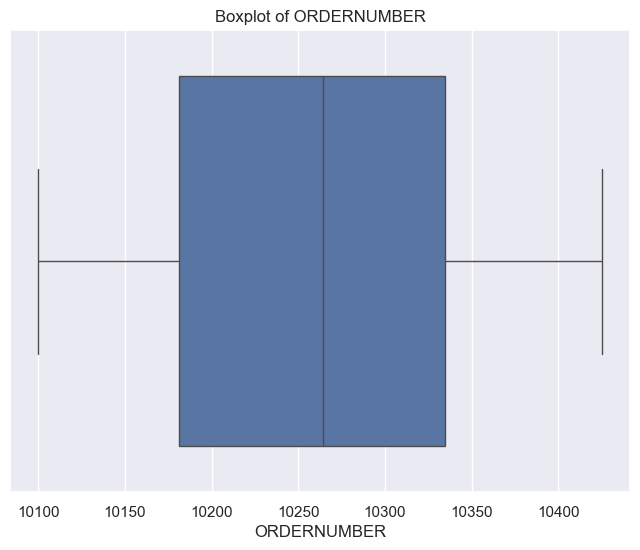

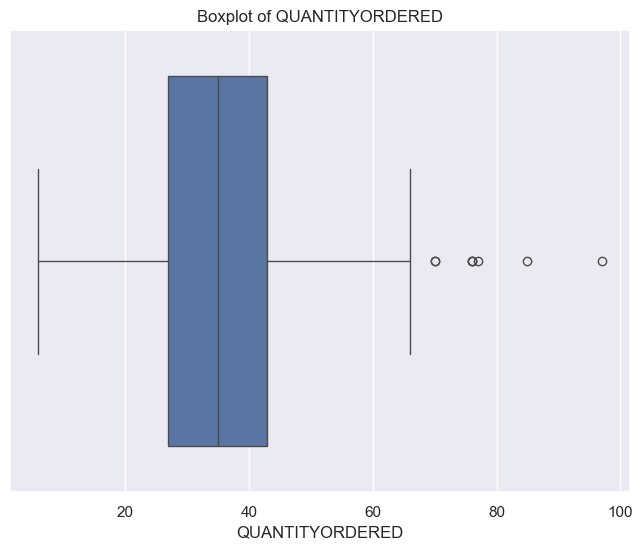

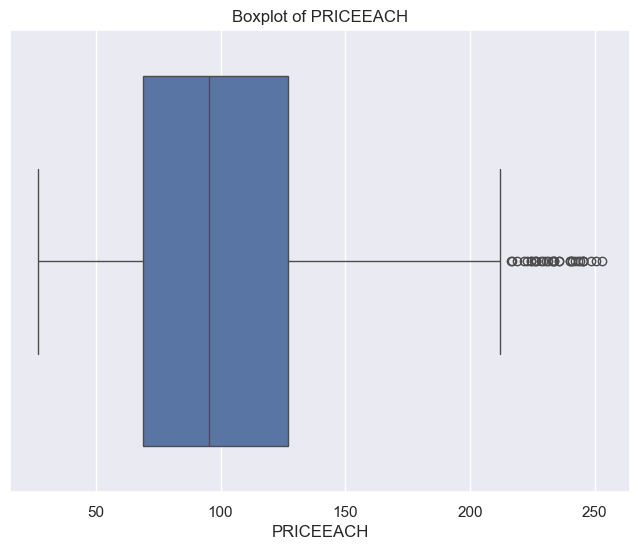

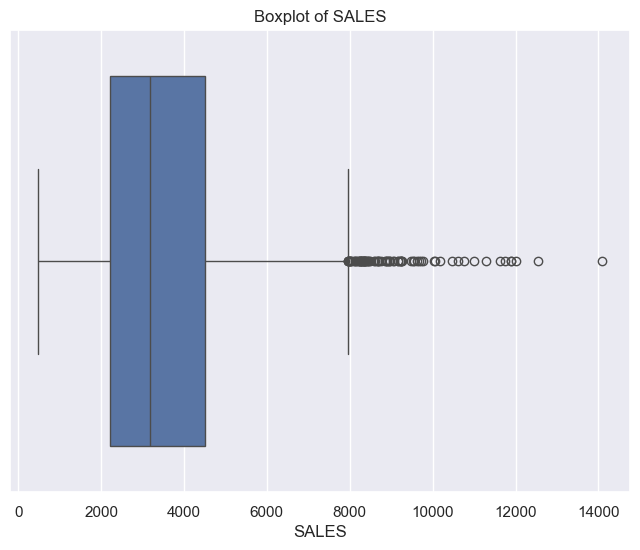

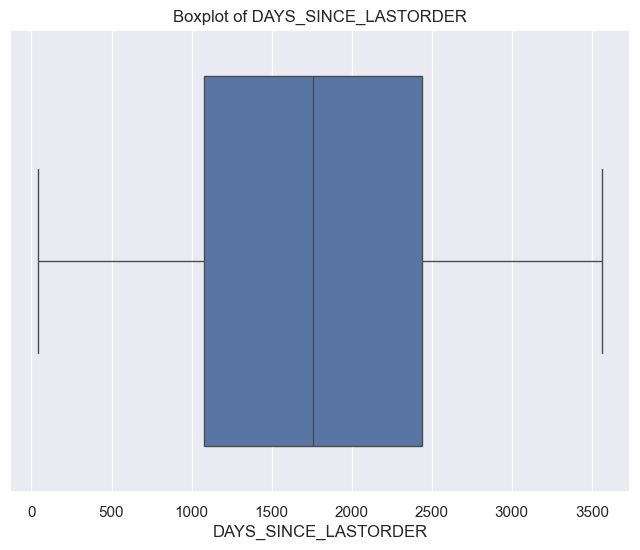

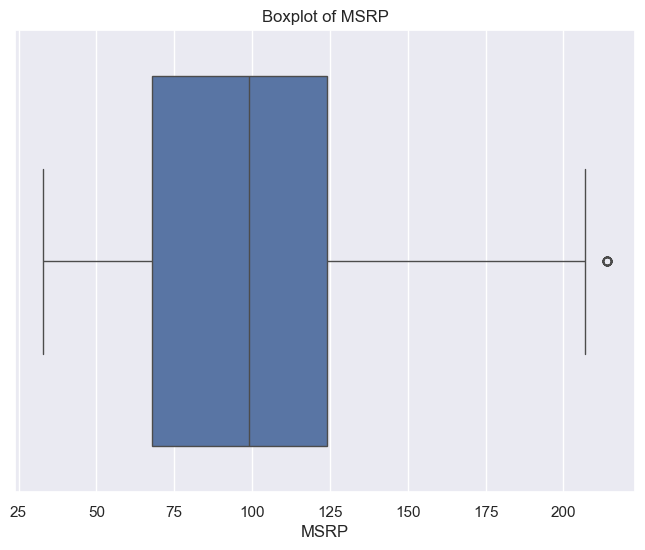

In [12]:
#4.	Check for the outliers in all numerical variables using box Plot
import matplotlib.pyplot as plt
import numpy as np
# Check for outliers in numerical variables using boxplots
numerical_cols = autosales_df.select_dtypes(include=np.number).columns
numerical_cols

for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x=autosales_df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [13]:
#5.	Find the total number of unique customers and unique countries.
unique_customers = autosales_df['CUSTOMERNAME'].nunique()
unique_countries = autosales_df['COUNTRY'].nunique()
print(f"Total number of unique customers: {unique_customers}")
print(f"Total number of unique countries: {unique_countries}")
print("unique customers:", pd.unique(autosales_df[['CUSTOMERNAME']].values.ravel()))
print("unique countries:", pd.unique(autosales_df[['COUNTRY']].values.ravel()))

Total number of unique customers: 89
Total number of unique countries: 19
unique customers: ['Land of Toys Inc.' 'Reims Collectables' 'Lyon Souveniers'
 'Toys4GrownUps.com' 'Technics Stores Inc.' 'Daedalus Designs Imports'
 'Herkku Gifts' 'Auto Canal Petit' 'Australian Collectors, Co.'
 'Vitachrome Inc.' 'Tekni Collectables Inc.' 'Gift Depot Inc.'
 'La Rochelle Gifts' "Marta's Replicas Co." 'Toys of Finland, Co.'
 'Baane Mini Imports' 'Diecast Classics Inc.' 'Salzburg Collectables'
 'Souveniers And Things Co.' 'FunGiftIdeas.com' 'UK Collectables, Ltd.'
 'Euro Shopping Channel' 'Volvo Model Replicas, Co'
 'Corrida Auto Replicas, Ltd' 'Dragon Souveniers, Ltd.'
 'Classic Legends Inc.' 'Australian Gift Network, Co'
 'Classic Gift Ideas, Inc' 'Saveley & Henriot, Co.'
 'Canadian Gift Exchange Network' 'West Coast Collectables Co.'
 'Cambridge Collectables Co.' 'Super Scale Inc.' 'Tokyo Collectables, Ltd'
 'Amica Models & Co.' 'Scandinavian Gift Ideas' 'Auto Assoc. & Cie.'
 'Mini Gifts Distri

In [14]:
#6.	Convert ORDERDATE into a datetime format. Extract Year and Month as new columns
autosales_df['ORDERDATE'] = pd.to_datetime(autosales_df['ORDERDATE'],format='%d-%m-%Y',dayfirst=True)
# Extract Year into a new column ORDERYear
autosales_df['ORDERYear'] = autosales_df['ORDERDATE'].dt.year

# Extract Month into a new column ORDERMonth
autosales_df['ORDERMonth'] = autosales_df['ORDERDATE'].dt.month
print(" 'ORDERDATE' column converted to datetime and 'ORDERYear' and 'ORDERMonth' columns extracted. Displaying the first few rows with new columns:")
display(autosales_df[['ORDERDATE', 'ORDERYear', 'ORDERMonth']].head())

 'ORDERDATE' column converted to datetime and 'ORDERYear' and 'ORDERMonth' columns extracted. Displaying the first few rows with new columns:


,ORDERDATE,ORDERYear,ORDERMonth
0,2018-02-24,2018,2
1,2018-05-07,2018,5
2,2018-07-01,2018,7
3,2018-08-25,2018,8
4,2018-10-28,2018,10


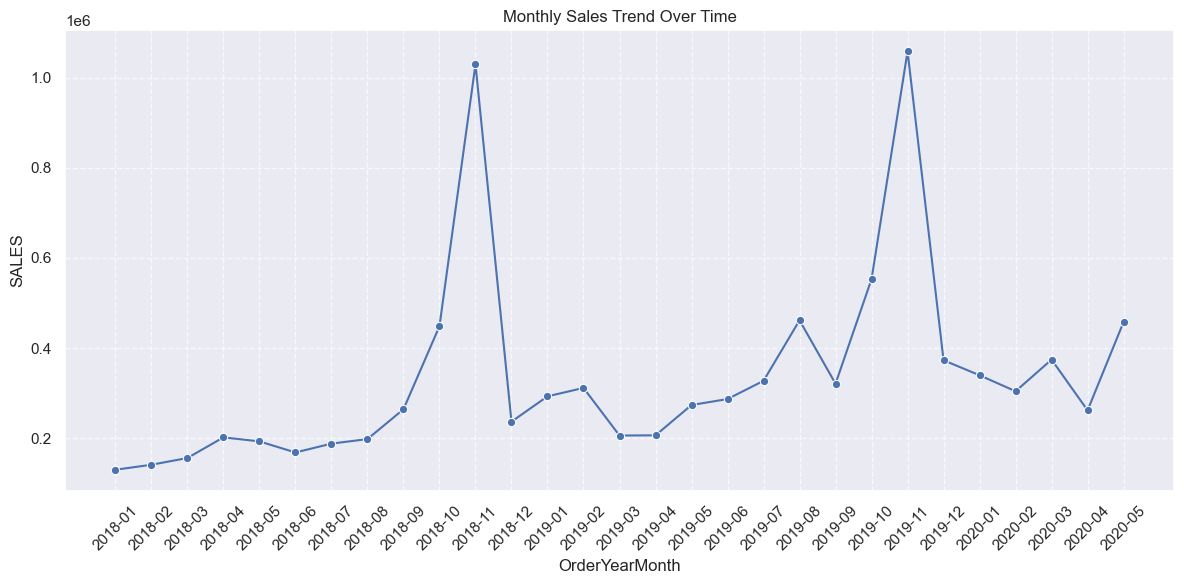

In [15]:
#7.	Create a visualization showing monthly sales trend over time.
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate monthly sales
monthly_sales = autosales_df.groupby(['ORDERYear', 'ORDERMonth'])['SALES'].sum().reset_index()

# Create a combined 'YearMonth' column for better chart creation
monthly_sales['OrderYearMonth'] = monthly_sales['ORDERYear'].astype(str) + '-' + monthly_sales['ORDERMonth'].astype(str).str.zfill(2) 

# Sort  YearMonth vslues to ensure order
monthly_sales = monthly_sales.sort_values(by='OrderYearMonth')

# Create the plot
plt.figure(figsize=(12, 6))
sns.lineplot(x='OrderYearMonth', y='SALES', data=monthly_sales, marker='o')
plt.title('Monthly Sales Trend Over Time')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [16]:
# 8.	Find the total sales by country and identify the top 3 countries by sales.
sales_by_country = autosales_df.groupby('COUNTRY')['SALES'].sum().reset_index()
sales_by_country = sales_by_country.sort_values(by='SALES', ascending=False)
print("Total Sales by top 3 Country:")
sales_by_country.head(3)

Total Sales by top 3 Country:


,COUNTRY,SALES
18,USA,3355575.69
14,Spain,1215686.92
6,France,1110916.52


In [17]:
#9.	Calculate the average order value (SALES) for each DEALSIZE. Which deal size contributes the most revenue?
avg_sales_by_dealsize = autosales_df.groupby('DEALSIZE')['SALES'].mean().reset_index()

# Sort in descending order to find the deal size with the most revenue
avg_sales_by_dealsize = avg_sales_by_dealsize.sort_values(by='SALES', ascending=False)

print("Average Order Value (SALES) by DEALSIZE:")
display(avg_sales_by_dealsize)

print("\nDEALSIZE contributing the most revenue (highest average sales):")
display(avg_sales_by_dealsize.head(1))


Average Order Value (SALES) by DEALSIZE:


,DEALSIZE,SALES
0,Large,8282.607895
1,Medium,4396.761653
2,Small,2062.627480



DEALSIZE contributing the most revenue (highest average sales):


,DEALSIZE,SALES
0,Large,8282.607895


In [18]:
#10.	Identify and count items where the selling price is higher than MSRP.

# Identify items where selling price is higher than MSRP
items_higher_price = autosales_df[autosales_df['PRICEEACH'] > autosales_df['MSRP']]
# Count these items
count_higher_price_items = len(items_higher_price)
print(f"Number of items where selling price is higher than MSRP: {count_higher_price_items}")

if count_higher_price_items > 0:
 print("\nFirst few items where selling price is higher than MSRP:")
 display(items_higher_price[['PRODUCTLINE', 'PRODUCTCODE', 'PRICEEACH', 'MSRP']].head(10))

Number of items where selling price is higher than MSRP: 1398

First few items where selling price is higher than MSRP:


,PRODUCTLINE,PRODUCTCODE,PRICEEACH,MSRP
0,Motorcycles,S10_1678,95.70,95
4,Motorcycles,S10_1678,96.66,95
6,Motorcycles,S10_1678,114.84,95
7,Motorcycles,S10_1678,114.84,95
8,Motorcycles,S10_1678,107.18,95
9,Motorcycles,S10_1678,101.44,95
10,Motorcycles,S10_1678,113.88,95
11,Motorcycles,S10_1678,108.14,95
13,Motorcycles,S10_1678,113.88,95
14,Motorcycles,S10_1678,112.93,95


C:\Users\richa\AppData\Local\Temp\ipykernel_30604\3764135843.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='PRODUCTLINE', y='SALES', data=sales_by_productline, palette='cubehelix')


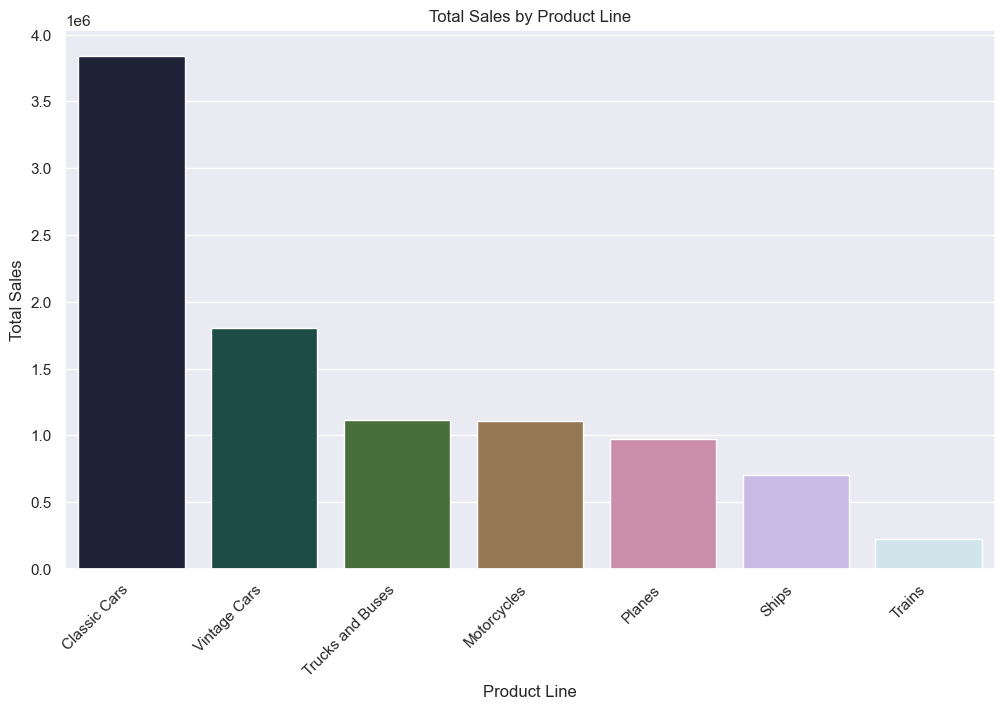

In [19]:
# 11.	Create a bar chart showing total sales by product line
sales_by_productline = autosales_df.groupby('PRODUCTLINE')['SALES'].sum().reset_index()

# Sort for better visualization
sales_by_productline = sales_by_productline.sort_values(by='SALES', ascending=False)

# Create the bar chart
plt.figure(figsize=(12, 7))
sns.barplot(x='PRODUCTLINE', y='SALES', data=sales_by_productline, palette='cubehelix')
plt.title('Total Sales by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right') # Rotate labels if they overlap
plt.show()

Correlation Matrix:


,QUANTITYORDERED,PRICEEACH,SALES
QUANTITYORDERED,1.000000,0.010161,0.553359
PRICEEACH,0.010161,1.000000,0.808287
SALES,0.553359,0.808287,1.000000


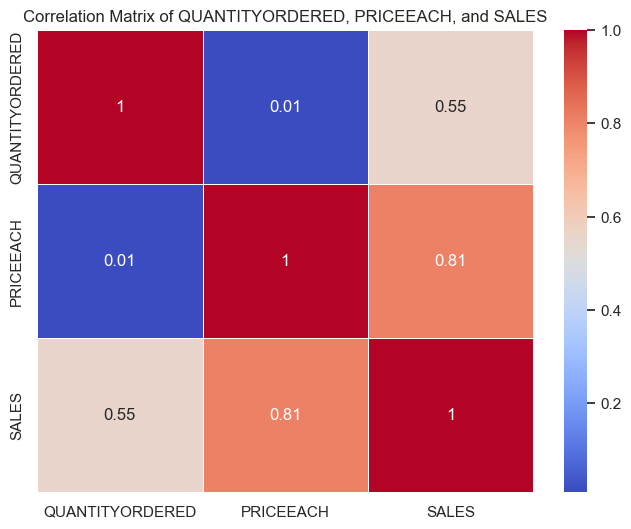

In [20]:
# 12.	Find the relationship between QUANTITYORDERED, PRICEEACH, SALES. Create a correlation matrix and visualize it using a heatmap.
# Select relevant columns
correlation_data = autosales_df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

# Calculate the correlation matrix
correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of QUANTITYORDERED, PRICEEACH, and SALES')
plt.show()

In [24]:
# 13.	Find customers whose last order was more than the average days using DAYS_SINCE_LASTORDER and print customer name and days since last order.
# Calculate the average days since last order
average_days_since_last_order = autosales_df['DAYS_SINCE_LASTORDER'].mean()

print(f"Average days since last order: {average_days_since_last_order}")

# Filter customers whose last order was more than the average days
customers_long_since_order = autosales_df[autosales_df['DAYS_SINCE_LASTORDER'] > average_days_since_last_order]

print("\nCustomers whose last order was more than the average days:")
display(customers_long_since_order[['CUSTOMERNAME', 'DAYS_SINCE_LASTORDER']].head())
print(f"\nTotal number of such customers: {len(customers_long_since_order)}")

Average days since last order: 1757.085911903895

Customers whose last order was more than the average days:


,CUSTOMERNAME,DAYS_SINCE_LASTORDER
922,Baane Mini Imports,1776
947,Danish Wholesale Imports,1788
972,Euro Shopping Channel,1824
973,Motor Mint Distributors Inc.,1787
974,"La Corne D'abondance, Co.",1766



Total number of such customers: 1379


In [25]:
# 14.	Identify customers who have placed more than one order. Print customer name and number of orders.

# Group by customer and count unique order numbers
customer_order_counts = autosales_df.groupby('CUSTOMERNAME')['ORDERNUMBER'].nunique().reset_index()
  
# Filter for customers with more than one order
customers_multiple_orders = customer_order_counts[customer_order_counts['ORDERNUMBER'] > 1]

print("Customers who have placed more than one order:")
display(customers_multiple_orders.head(10))
print(f"\nTotal number of customers with multiple orders: {len(customers_multiple_orders)}")

Customers who have placed more than one order:


,CUSTOMERNAME,ORDERNUMBER
0,"AV Stores, Co.",3
1,Alpha Cognac,3
2,Amica Models & Co.,2
3,"Anna's Decorations, Ltd",4
4,Atelier graphique,3
5,"Australian Collectables, Ltd",3
6,"Australian Collectors, Co.",5
7,"Australian Gift Network, Co",3
8,Auto Assoc. & Cie.,2
9,Auto Canal Petit,3



Total number of customers with multiple orders: 88


In [26]:
#15.	Check the missing records in each column.
autosales_df.isnull().sum().sort_values(ascending=False)

ORDERNUMBER             0
QUANTITYORDERED         0
PRICEEACH               0
SALES                   0
ORDERDATE               0
DAYS_SINCE_LASTORDER    0
STATUS                  0
PRODUCTLINE             0
MSRP                    0
PRODUCTCODE             0
CUSTOMERNAME            0
ADDRESSLINE1            0
CITY                    0
POSTALCODE              0
COUNTRY                 0
CONTACTLASTNAME         0
CONTACTFIRSTNAME        0
DEALSIZE                0
ORDERYear               0
ORDERMonth              0
dtype: int64

In [27]:
#16.	Create 2 Dataframes – 1 for numerical and 1 for categorical using pandas.
# Create Categorical DataFrame
df=autosales_df
autosales_df.dtypes
cat_col = [fea for fea in df.columns if df[fea].dtypes =='object']
cat_col
cat_data = df[cat_col] # here dataframe of object type catagorical data
cat_data
print("\nCategorical DataFrame:")
display(cat_data.head())


Categorical DataFrame:


,STATUS,PRODUCTLINE,PRODUCTCODE,CUSTOMERNAME,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,Shipped,Motorcycles,S10_1678,Land of Toys Inc.,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,Shipped,Motorcycles,S10_1678,Reims Collectables,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,Shipped,Motorcycles,S10_1678,Lyon Souveniers,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,Shipped,Motorcycles,S10_1678,Toys4GrownUps.com,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,Shipped,Motorcycles,S10_1678,Technics Stores Inc.,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


In [28]:
# Create Numerical Dataframe
num_col = [fea for fea in df.columns if df[fea].dtypes !='object']
num_data=df[num_col]
print("\nNumerical DataFrame:")
display(num_data.head())


Numerical DataFrame:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,MSRP,ORDERYear,ORDERMonth
0,10107,30,95.70,2871.00,2018-02-24,828,95,2018,2
1,10121,34,81.35,2765.90,2018-05-07,757,95,2018,5
2,10134,41,94.74,3884.34,2018-07-01,703,95,2018,7
3,10145,45,83.26,3746.70,2018-08-25,649,95,2018,8
4,10168,36,96.66,3479.76,2018-10-28,586,95,2018,10


In [31]:
# 17.	Rename the ORDERNUMBER as order_number and QUANTITYORDERED as qty_ordered.
autosales_df.rename(columns={'ORorder_number': 'order_number', 'QUANTITYORDERED': 'qty_ordered'}, inplace=True)
print("Columns 'ORDERNUMBER' and 'QUANTITYORDERED' renamed successfully. Displaying the first few rows with new column names:")
display(autosales_df.head(10))

Columns 'ORDERNUMBER' and 'QUANTITYORDERED' renamed successfully. Displaying the first few rows with new column names:


,ORDERNUMBER,qty_ordered,PRICEEACH,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,ORDERYear,ORDERMonth
0,10107,30,95.70,2871.00,2018-02-24,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small,2018,2
1,10121,34,81.35,2765.90,2018-05-07,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small,2018,5
2,10134,41,94.74,3884.34,2018-07-01,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium,2018,7
3,10145,45,83.26,3746.70,2018-08-25,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium,2018,8
4,10168,36,96.66,3479.76,2018-10-28,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium,2018,10
5,10180,29,86.13,2497.77,2018-11-11,573,Shipped,Motorcycles,95,S10_1678,Daedalus Designs Imports,"184, chausse de Tournai",Lille,59000,France,Rance,Martine,Small,2018,11
6,10188,48,114.84,5512.32,2018-11-18,567,Shipped,Motorcycles,95,S10_1678,Herkku Gifts,"Drammen 121, PR 744 Sentrum",Bergen,N 5804,Norway,Oeztan,Veysel,Medium,2018,11
7,10211,41,114.84,4708.44,2019-01-15,510,Shipped,Motorcycles,95,S10_1678,Auto Canal Petit,"25, rue Lauriston",Paris,75016,France,Perrier,Dominique,Medium,2019,1
8,10223,37,107.18,3965.66,2019-02-20,475,Shipped,Motorcycles,95,S10_1678,"Australian Collectors, Co.",636 St Kilda Road,Melbourne,3004,Australia,Ferguson,Peter,Medium,2019,2
9,10237,23,101.44,2333.12,2019-04-05,432,Shipped,Motorcycles,95,S10_1678,Vitachrome Inc.,2678 Kingston Rd.,NYC,10022,USA,Frick,Michael,Small,2019,4


In [32]:
# 18.	For the numerical dataframe created in Q16, perform the feature scaling (using standard scaler) to bring all variables on same scale.
# Before feature scaling
num_data

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,MSRP,ORDERYear,ORDERMonth
0,10107,30,95.70,2871.00,2018-02-24,828,95,2018,2
1,10121,34,81.35,2765.90,2018-05-07,757,95,2018,5
2,10134,41,94.74,3884.34,2018-07-01,703,95,2018,7
3,10145,45,83.26,3746.70,2018-08-25,649,95,2018,8
4,10168,36,96.66,3479.76,2018-10-28,586,95,2018,10
...,...,...,...,...,...,...,...,...,...
2742,10350,20,112.22,2244.40,2019-12-02,2924,54,2019,12
2743,10373,29,137.19,3978.51,2020-01-31,2865,54,2020,1
2744,10386,43,125.99,5417.57,2020-03-01,2836,54,2020,3
2745,10397,34,62.24,2116.16,2020-03-28,2810,54,2020,3


In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
# Apply StandardScaler
standard_scaler = StandardScaler()
X_standard_scaled = standard_scaler.fit_transform(num_data)
X_standard_scaled

In [ ]:
# Convert the scaled data back to DataFrame
df_standard_scaled = pd.DataFrame(X_standard_scaled,columns=num_data.columns)
df_standard_scaled.round(2)

In [33]:
#19.	Check for the skewness in all numerical variables and tag them as low skewed, moderately skewed and highly skewed.
# Original Skewness
num_data
original_skewness = df[['qty_ordered', 'PRICEEACH','SALES','DAYS_SINCE_LASTORDER','MSRP']].skew()
print("Original Skewness:")
print(original_skewness)


Original Skewness:
qty_ordered             0.369286
PRICEEACH               0.697222
SALES                   1.155940
DAYS_SINCE_LASTORDER   -0.002983
MSRP                    0.575646
dtype: float64


In [34]:

# Select only numerical columns and skewness
numerical_cols = autosales_df.select_dtypes(include=['int64', 'float64']).columns

print("Skewness for numerical variables:")
skewness_results = {}

for col in numerical_cols:
    skewness = autosales_df[col].skew()

   # Classify skewness
    if abs(skewness) < 0.5:
     category = 'Low Skewed'
    elif 0.5 <= abs(skewness) < 1:
     category = 'Moderately Skewed'
    else:
     category = 'Highly Skewed'

    skewness_results[col] = {'Skewness Value': skewness, 'Category': category}

 # Display results in a DataFrame for better readability
skewness_df = pd.DataFrame.from_dict(skewness_results, orient='index')
skewness_df.index.name = 'Variable'
display(skewness_df)

Skewness for numerical variables:


,Skewness Value,Category
Variable,,
ORDERNUMBER,-0.006995,Low Skewed
qty_ordered,0.369286,Low Skewed
PRICEEACH,0.697222,Moderately Skewed
SALES,1.155940,Highly Skewed
DAYS_SINCE_LASTORDER,-0.002983,Low Skewed
MSRP,0.575646,Moderately Skewed


In [35]:
# 20.	For highly skewed variables, perform the transformation techniques and make the less/moderately skewed.
from scipy.stats import boxcox
# Log Transformation
autosales_df['log_SALES'] = np.log(autosales_df['SALES'] + 1) 

# Square Root Transformation
autosales_df['sqrt_SALES'] = np.sqrt(autosales_df['SALES'])

# Cube Root Transformation
autosales_df['cqrt_SALES'] = np.cbrt(autosales_df['SALES'])

#boxcox transformation
autosales_df['boxcox_Sales'],lmbda = boxcox(autosales_df['SALES'] + 1) 

In [36]:
# Calculate skewness after transformations
transformed_skewness = autosales_df[['log_SALES', 'sqrt_SALES', 'cqrt_SALES', 'boxcox_Sales']].skew()
print("Transformed Skewness:")
print(transformed_skewness)

Transformed Skewness:
log_SALES      -0.208221
sqrt_SALES      0.468527
cqrt_SALES      0.246178
boxcox_Sales   -0.006375
dtype: float64


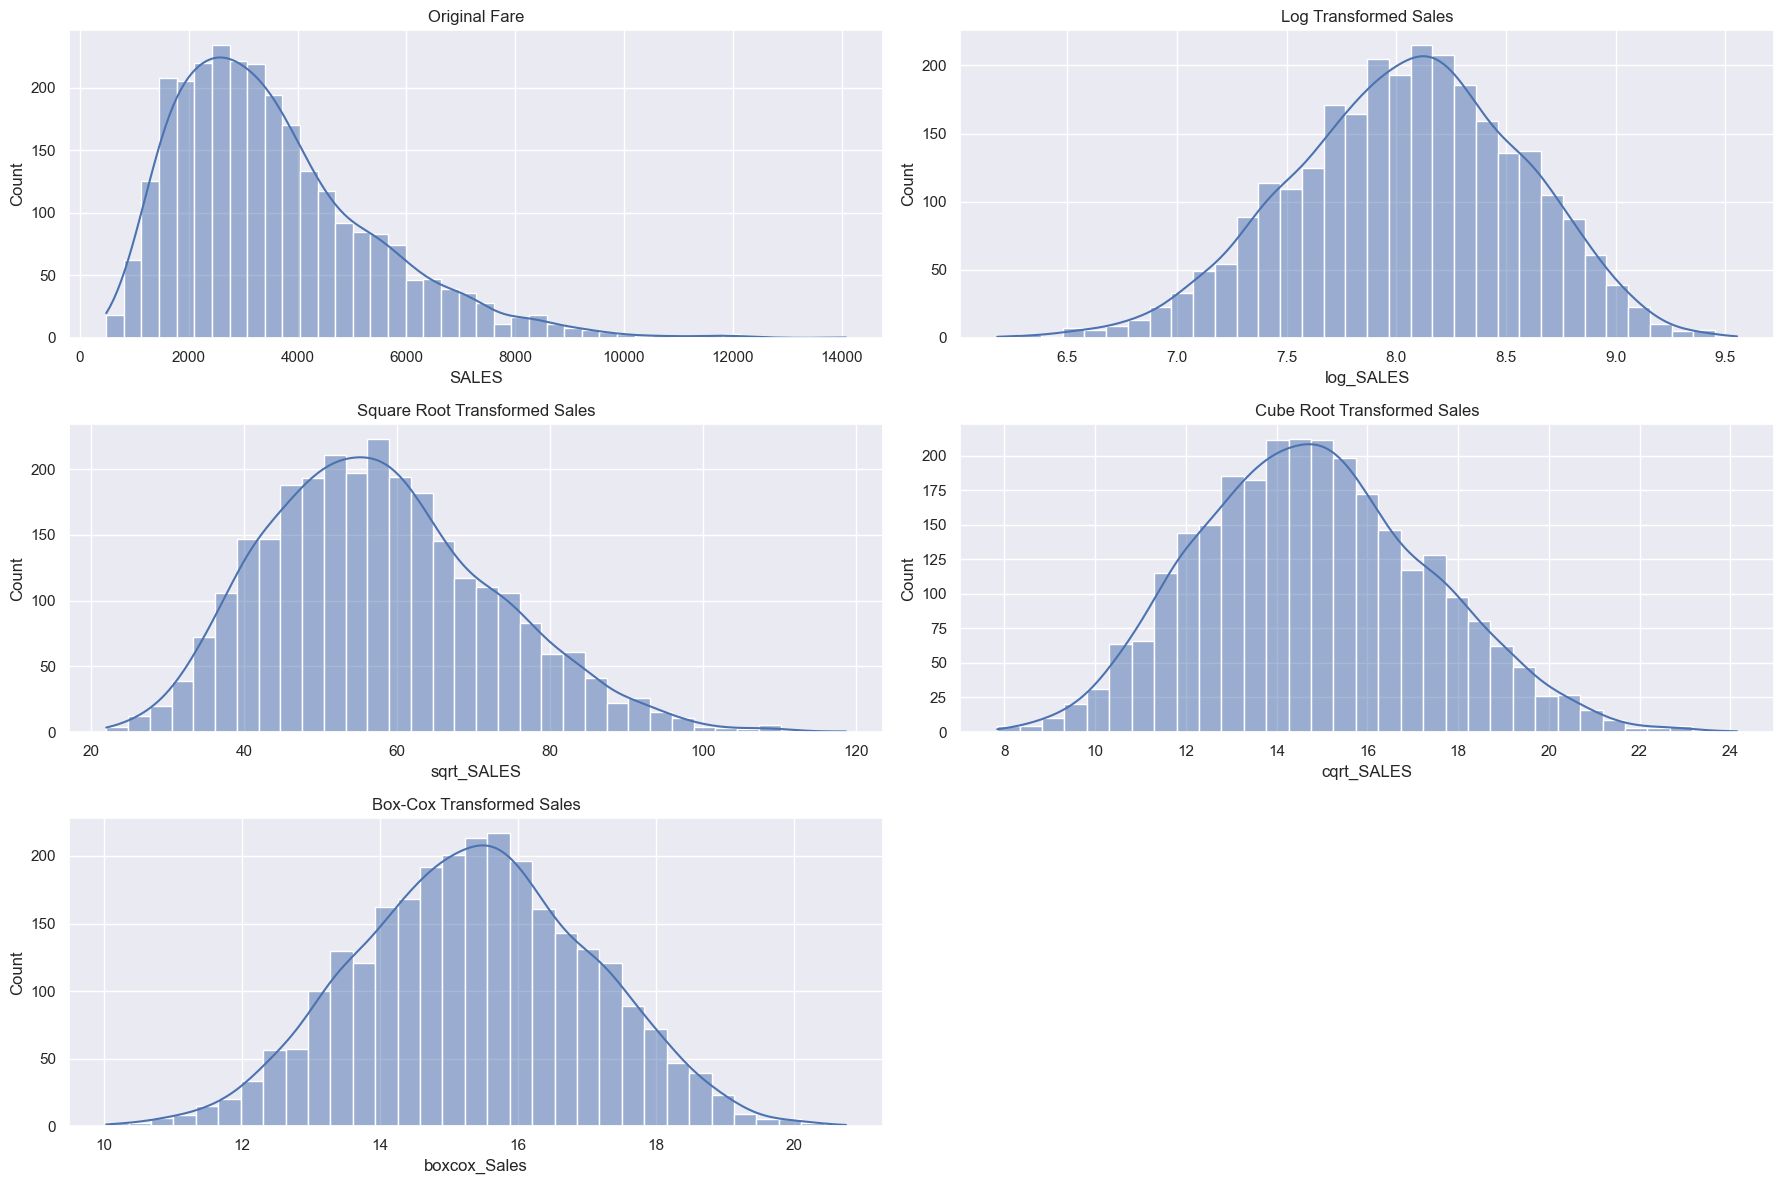

In [37]:
# Visualize the transformed distributions
plt.figure(figsize=(18, 12))

# Original Distribution
plt.subplot(3, 2, 1)
sns.histplot(autosales_df['SALES'], kde=True)
plt.title('Original Fare')

# Log Transformation
plt.subplot(3, 2, 2)
sns.histplot(autosales_df['log_SALES'], kde=True)
plt.title('Log Transformed Sales')

# Square Root Transformation
plt.subplot(3, 2, 3)
sns.histplot(autosales_df['sqrt_SALES'], kde=True)
plt.title('Square Root Transformed Sales')

# Cube Root Transformation
plt.subplot(3, 2, 4)
sns.histplot(autosales_df['cqrt_SALES'], kde=True)
plt.title('Cube Root Transformed Sales')

# Box-Cox Transformation
plt.subplot(3, 2, 5)
sns.histplot(autosales_df['boxcox_Sales'], kde=True)
plt.title('Box-Cox Transformed Sales')

plt.tight_layout()
plt.show()